
Dataset Created Successfully!

   Income  Debts  Payment_History  Loan_Amount  Age  Creditworthy
0  141958  51919                1        20419   48             1
1   35795  27103                0        40017   42             0
2   20860  36188                0        40577   64             0
3  123694   5845                0         7921   50             1
4  148106  36674                0         9676   52             1

Model Accuracy: 0.984

Classification Report:

              precision    recall  f1-score   support

           0       0.98      0.97      0.98       337
           1       0.99      0.99      0.99       663

    accuracy                           0.98      1000
   macro avg       0.98      0.98      0.98      1000
weighted avg       0.98      0.98      0.98      1000



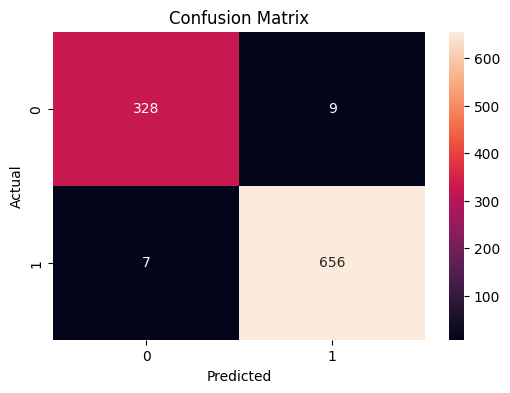

In [2]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
np.random.seed(42)
n=5000
income=np.random.randint(20000, 150000, n)
debts=np.random.randint(0, 80000, n)
payment_history=np.random.randint(0, 2, n)
loan_amount=np.random.randint(5000, 50000, n)
age=np.random.randint(18, 65, n)
credit_score=((income / 1000)-(debts / 2000)+(payment_history * 20)-(loan_amount / 5000)+(age / 10))
target=np.where(credit_score > 50, 1, 0)
df=pd.DataFrame({'Income': income,'Debts': debts,'Payment_History': payment_history,'Loan_Amount': loan_amount,'Age': age,'Creditworthy': target})
df.to_csv("dataset.csv", index=False)
print("\nDataset Created Successfully!\n")
print(df.head())
X=df.drop('Creditworthy', axis=1)
y=df['Creditworthy']
X_train, X_test, y_train, y_test=train_test_split(X, y,test_size=0.2,random_state=42)
model=DecisionTreeClassifier(criterion='entropy')
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print("\nModel Accuracy:", accuracy)
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred))
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()